# 1. Configuração

In [139]:
from pathlib import Path

import numpy as np
import cv2 # Processamento de imagens
import matplotlib.pyplot as plt
import pandas as pd

# Métrica para comparação dos rostos
from sklearn.metrics.pairwise import cosine_similarity
# Modelo pré-treinado para gerar embeddings faciais
from deepface import DeepFace

In [140]:
# Configurações do projeto
MODEL_NAME = "Facenet512"

print("Ambiente configurado com sucesso!")
print(f"Modelo facial selecionado: {MODEL_NAME}")

Ambiente configurado com sucesso!
Modelo facial selecionado: Facenet512


# 2. Carregar dataset

In [ ]:
DATASET_DIR = Path("dataset")

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"O diretório '{DATASET_DIR}' não foi encontrado."
    )

print(f"Dataset encontrado em: {DATASET_DIR.resolve()}")

Dataset encontrado em: C:\Users\gabis\fiap-fase6-implementing-facial-recognition\dataset


In [150]:
CONHECIDOS_DIR = DATASET_DIR / "conhecidos"

dataset = {}

for pessoa_dir in CONHECIDOS_DIR.iterdir():

    if not pessoa_dir.is_dir():
        continue

    treino_dir = pessoa_dir / "treino"
    teste_dir = pessoa_dir / "teste"

    imagens_treino = []
    imagens_teste = []

    if treino_dir.exists():
        imagens_treino = list(treino_dir.glob("*.jpg"))
        imagens_treino += list(treino_dir.glob("*.jpeg"))
        imagens_treino += list(treino_dir.glob("*.png"))

    if teste_dir.exists():
        imagens_teste = list(teste_dir.glob("*.jpg"))
        imagens_teste += list(teste_dir.glob("*.jpeg"))
        imagens_teste += list(teste_dir.glob("*.png"))

    dataset[pessoa_dir.name] = {
        "treino": imagens_treino,
        "teste": imagens_teste
    }

Validação

In [152]:
dataset_valido = True

for pessoa, dados in dataset.items():

    if len(dados["treino"]) < 4:
        print(
            f"Pessoa '{pessoa}' não possui "
            "4 imagens de treinamento."
        )
        dataset_valido = False

    if dados["teste"] is None:
        print(
            f"Pessoa '{pessoa}' não possui imagem de teste."
        )
        dataset_valido = False

if dataset_valido:
    print("\nDataset validado com sucesso!")
else:
    print("\nExistem problemas na organização do dataset.")


Dataset validado com sucesso!


# 3. Detecção facial

In [153]:
DETECTOR_BACKEND = "opencv"

print(f"Detector facial selecionado: {DETECTOR_BACKEND}")

Detector facial selecionado: opencv


In [154]:
def detectar_rosto(caminho_imagem):

    # Carrega a imagem original
    imagem = cv2.imread(str(caminho_imagem))

    if imagem is None:
        raise ValueError(
            f"Não foi possível carregar a imagem: {caminho_imagem}"
        )

    # Detecta as faces presentes na imagem
    faces = DeepFace.extract_faces(
        img_path=str(caminho_imagem),
        detector_backend=DETECTOR_BACKEND,
        enforce_detection=True,
        align=True
    )
    
    # Para nosso dataset esperamos exatamente um rosto
    if len(faces) != 1:
        raise ValueError(
            f"Esperava exatamente 1 rosto em '{caminho_imagem.name}, mas foram encontrados {len(faces)}."
        )

    face = faces[0]

    # Coordenadas retornadas pelo detector
    area = face["facial_area"]

    x = area["x"]
    y = area["y"]
    w = area["w"]
    h = area["h"]

    # Recorta o rosto diretamente da imagem original
    rosto_recortado = imagem[y:y+h, x:x+w]

    return {
        "imagem_original": imagem,
        "bounding_box": (x, y, w, h),
        "rosto": rosto_recortado
    }

### Bounding Box

O **bounding box** é o retângulo que delimita a região da imagem onde o rosto foi detectado. Ele é representado por quatro valores: **x, y, w e h**.

* **x**: posição horizontal onde o rosto começa;
* **y**: posição vertical onde o rosto começa;
* **w (width)**: largura da região detectada;
* **h (height)**: altura da região detectada.

Esses valores são expressos em **pixels** e permitem localizar exatamente a face dentro da imagem original.

Neste projeto, as coordenadas são obtidas a partir do campo `facial_area` retornado pelo `DeepFace`. Em seguida, são utilizadas para recortar apenas a região correspondente ao rosto:

```python
rosto_recortado = imagem[y:y+h, x:x+w]
```

Dessa forma, o *bounding box* permite separar a face do restante da imagem, facilitando as etapas seguintes do reconhecimento facial, como a geração dos **embeddings faciais** e a comparação entre os rostos.


In [155]:
for pessoa, dados in dataset.items():
    print(pessoa)
    print("Treino:", dados["treino"])
    print("Teste:", dados["teste"])
    print()

Gabriela
Treino: [WindowsPath('dataset/conhecidos/Gabriela/treino/1_gabriela.jpg'), WindowsPath('dataset/conhecidos/Gabriela/treino/2_gabriela.jpg'), WindowsPath('dataset/conhecidos/Gabriela/treino/3_gabriela.jpg'), WindowsPath('dataset/conhecidos/Gabriela/treino/4_gabriela.jpg')]
Teste: [WindowsPath('dataset/conhecidos/Gabriela/teste/5_gabriela.jpg')]

Tom Holland
Treino: [WindowsPath('dataset/conhecidos/Tom Holland/treino/1_tom.jpg'), WindowsPath('dataset/conhecidos/Tom Holland/treino/2_tom.jpg'), WindowsPath('dataset/conhecidos/Tom Holland/treino/3_tom.jpg'), WindowsPath('dataset/conhecidos/Tom Holland/treino/4_tom.jpg')]
Teste: [WindowsPath('dataset/conhecidos/Tom Holland/teste/5_tom.jpg')]

Zendaya
Treino: [WindowsPath('dataset/conhecidos/Zendaya/treino/2_zendaya.jpg'), WindowsPath('dataset/conhecidos/Zendaya/treino/4_zendaya.jpg'), WindowsPath('dataset/conhecidos/Zendaya/treino/1_zendaya.jpg.png'), WindowsPath('dataset/conhecidos/Zendaya/treino/3_zendaya.png')]
Teste: [WindowsPat

In [156]:
pessoa_teste = list(dataset.keys())[0]
imagem_teste = dataset[pessoa_teste]["treino"][0]

resultado = detectar_rosto(imagem_teste)

print(f"Pessoa: {pessoa_teste}")
print(f"Imagem: {imagem_teste.name}")
print(f"Bounding box: {resultado['bounding_box']}")

Pessoa: Gabriela
Imagem: 1_gabriela.jpg
Bounding box: (115, 250, 230, 230)


In [157]:
resultado

{'imagem_original': array([[[ 30,  49,  40],
         [ 33,  52,  43],
         [ 48,  67,  58],
         ...,
         [204, 200, 195],
         [204, 200, 195],
         [201, 197, 192]],
 
        [[ 32,  51,  42],
         [ 36,  55,  46],
         [ 43,  62,  53],
         ...,
         [ 99,  95,  90],
         [123, 119, 114],
         [150, 146, 141]],
 
        [[ 44,  63,  54],
         [ 35,  54,  45],
         [ 43,  62,  53],
         ...,
         [ 13,   9,   4],
         [ 13,   9,   4],
         [ 29,  25,  20]],
 
        ...,
 
        [[ 72, 101, 128],
         [ 71, 100, 127],
         [ 70,  99, 126],
         ...,
         [141, 144, 149],
         [161, 164, 169],
         [167, 170, 175]],
 
        [[ 72, 101, 128],
         [ 71, 100, 127],
         [ 70,  99, 126],
         ...,
         [ 17,  17,  23],
         [ 87,  90,  95],
         [135, 138, 143]],
 
        [[ 70,  99, 126],
         [ 69,  98, 125],
         [ 68,  97, 124],
         ...,
         

In [158]:
def desenhar_bounding_box(imagem, bounding_box):

    # Trabalhamos sobre uma cópia para não alterar a imagem original
    imagem_box = imagem.copy()

    x, y, w, h = bounding_box

    cv2.rectangle(
        imagem_box,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

    return imagem_box

Visualizando as 3 etapas juntas

In [159]:
def visualizar_deteccao(resultado, titulo="Detecção facial"):

    original = resultado["imagem_original"]

    com_box = desenhar_bounding_box(
        original,
        resultado["bounding_box"]
    )

    rosto = resultado["rosto"]

    # OpenCV trabalha em BGR.
    # Matplotlib espera RGB.
    original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    box_rgb = cv2.cvtColor(com_box, cv2.COLOR_BGR2RGB)
    rosto_rgb = cv2.cvtColor(rosto, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 4))

    # Imagem original
    plt.subplot(1, 3, 1)
    plt.imshow(original_rgb)
    plt.title("Imagem original")
    plt.axis("off")

    # Bounding box
    plt.subplot(1, 3, 2)
    plt.imshow(box_rgb)
    plt.title("Face detectada")
    plt.axis("off")

    # Rosto recortado
    plt.subplot(1, 3, 3)
    plt.imshow(rosto_rgb)
    plt.title("Rosto recortado")
    plt.axis("off")

    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

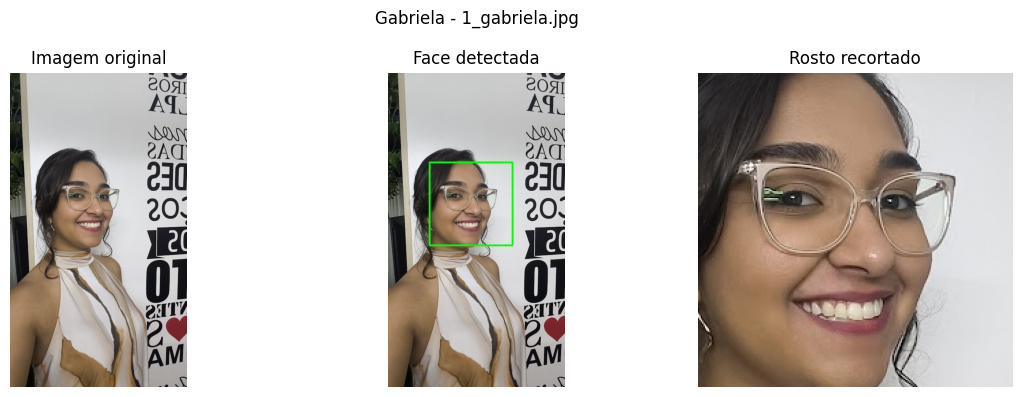

In [160]:
visualizar_deteccao(
    resultado,
    titulo=f"{pessoa_teste} - {imagem_teste.name}"
)

Executar para todas as imagens

In [162]:
resultados_deteccao = {}

for pessoa, dados in dataset.items():

    resultados_deteccao[pessoa] = {
        "treino": [],
        "teste": []
    }

    print(f"\nProcessando: {pessoa}")

    # Imagens de treinamento
    for caminho in dados["treino"]:

        try:
            resultado = detectar_rosto(caminho)

            resultados_deteccao[pessoa]["treino"].append({
                "arquivo": caminho,
                "resultado": resultado
            })

            print(f"  OK   | {caminho.name}")

        except Exception as erro:
            print(f"  ERRO | {caminho.name} | {erro}")

    # Imagens de teste
    for caminho in dados["teste"]:

        try:
            resultado = detectar_rosto(caminho)

            resultados_deteccao[pessoa]["teste"].append({
                "arquivo": caminho,
                "resultado": resultado
            })

            print(f"  OK   | {caminho.name} [TESTE]")

        except Exception as erro:
            print(f"  ERRO | {caminho.name} | {erro}")


Processando: Gabriela
  OK   | 1_gabriela.jpg
  OK   | 2_gabriela.jpg
  OK   | 3_gabriela.jpg
  OK   | 4_gabriela.jpg
  OK   | 5_gabriela.jpg [TESTE]

Processando: Tom Holland
  OK   | 1_tom.jpg
  OK   | 2_tom.jpg
  OK   | 3_tom.jpg
  OK   | 4_tom.jpg
  OK   | 5_tom.jpg [TESTE]

Processando: Zendaya
  OK   | 2_zendaya.jpg
  OK   | 4_zendaya.jpg
  OK   | 1_zendaya.jpg.png
  OK   | 3_zendaya.png
  OK   | 5_zendaya.png [TESTE]


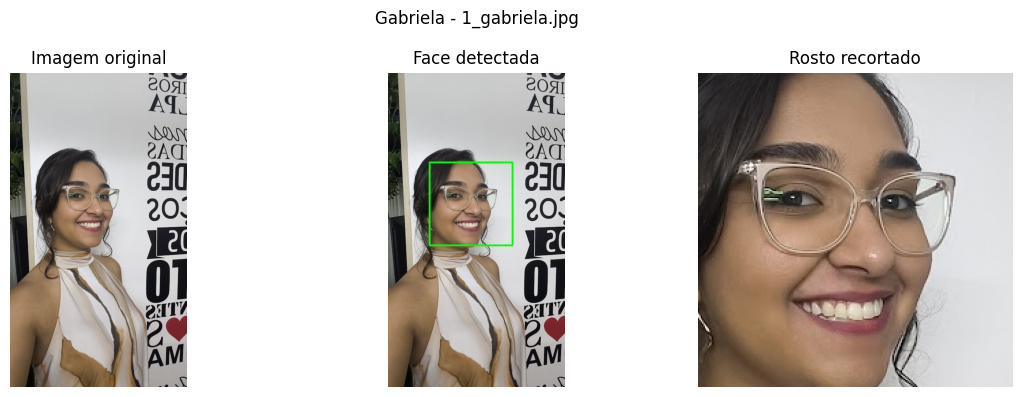

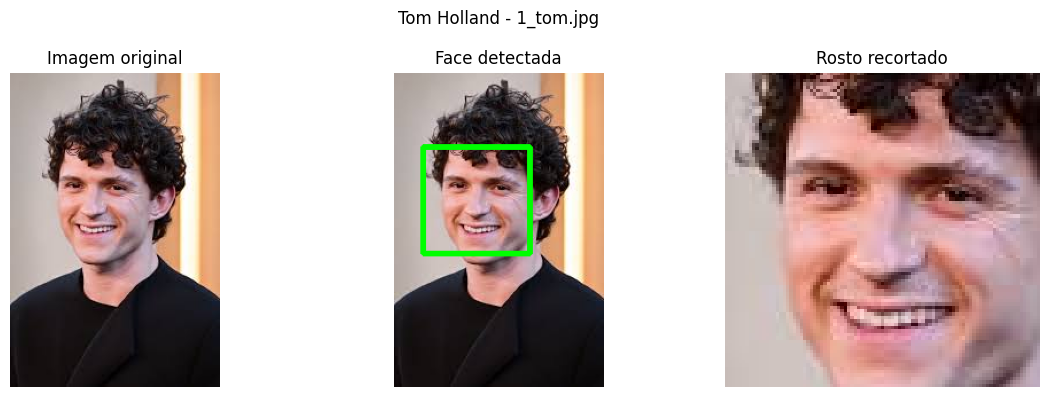

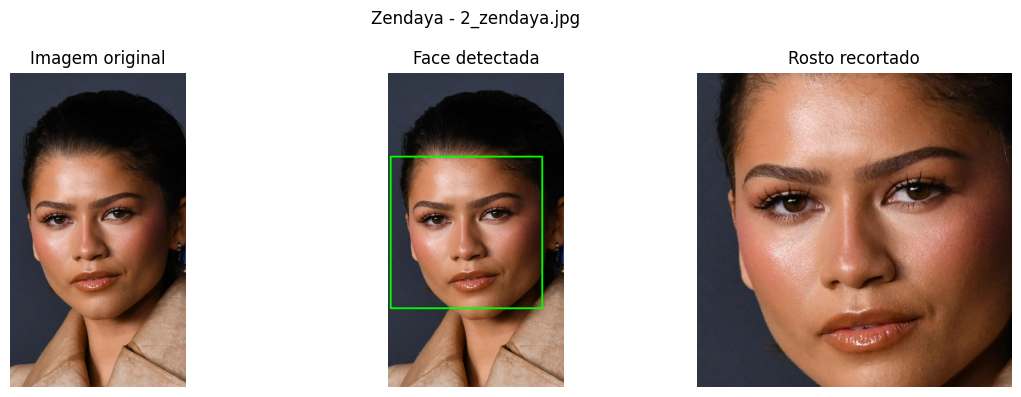

In [164]:
# Mostrando uma detecção de teste para cada pessoa
for pessoa, dados in resultados_deteccao.items():

    if dados["treino"]:

        exemplo = dados["treino"][0]

        visualizar_deteccao(
            exemplo["resultado"],
            titulo=f"{pessoa} - {exemplo['arquivo'].name}"
        )

# 4. Extração dos embeddings

In [165]:
def extrair_embedding(caminho_imagem):

    resultado = DeepFace.represent(
        img_path=str(caminho_imagem),
        model_name=MODEL_NAME,
        detector_backend=DETECTOR_BACKEND,
        enforce_detection=True,
        align=True
    )

    if len(resultado) != 1:
        raise ValueError(
            f"Esperava exatamente 1 rosto em '{caminho_imagem.name}', "
            f"mas foram encontrados {len(resultado)}."
        )

    embedding = np.array(
        resultado[0]["embedding"],
        dtype=np.float32
    )

    return embedding

In [166]:
pessoa_teste = list(dataset.keys())[0]
imagem = dataset[pessoa_teste]["treino"][0]

embedding = extrair_embedding(imagem)

print(f"Pessoa: {pessoa_teste}")
print(f"Imagem: {imagem.name}")
print(f"Dimensão do embedding: {embedding.shape}")
print(f"Primeiros valores: {embedding[:10]}")

Pessoa: Gabriela
Imagem: 1_gabriela.jpg
Dimensão do embedding: (512,)
Primeiros valores: [-1.4510919  -0.63364255 -0.6881694   0.41004482 -0.27874622 -0.77966833
  1.1937696  -0.9290272   1.1377896   0.16006611]


Esses números passam a representar matematicamente as caracteristicas faciais extraidas pelo nosso código/modelo

In [167]:
# Gerando embeddings para todas as imagens de treino
embeddings_treino = {}

for pessoa, dados in dataset.items():

    print(f"\nProcessando: {pessoa}")

    embeddings_pessoa = []

    for caminho in dados["treino"]:

        embedding = extrair_embedding(caminho)
        embeddings_pessoa.append(embedding)

        print(f"  OK | {caminho.name} " f"| dimensão: {embedding.shape}")

    embeddings_treino[pessoa] = embeddings_pessoa


Processando: Gabriela
  OK | 1_gabriela.jpg | dimensão: (512,)
  OK | 2_gabriela.jpg | dimensão: (512,)
  OK | 3_gabriela.jpg | dimensão: (512,)
  OK | 4_gabriela.jpg | dimensão: (512,)

Processando: Tom Holland
  OK | 1_tom.jpg | dimensão: (512,)
  OK | 2_tom.jpg | dimensão: (512,)
  OK | 3_tom.jpg | dimensão: (512,)
  OK | 4_tom.jpg | dimensão: (512,)

Processando: Zendaya
  OK | 2_zendaya.jpg | dimensão: (512,)
  OK | 4_zendaya.jpg | dimensão: (512,)
  OK | 1_zendaya.jpg.png | dimensão: (512,)
  OK | 3_zendaya.png | dimensão: (512,)


Para cada pessoa temos 4 vetores (foto X embedding)
Agora, calculamos a média de cada posição dos quatro vetores. Usamos a média para ter um **valor referência menos dependente de particularidades** de uma foto só (iluminição, expressão, angulação, etc)

In [168]:
perfis_faciais = {}

for pessoa, embeddings in embeddings_treino.items():

    matriz_embeddings = np.array(embeddings)
    embedding_medio = np.mean(matriz_embeddings, axis=0)
    perfis_faciais[pessoa] = embedding_medio

    print(f"{pessoa}: " f"{len(embeddings)} embeddings -> " f"perfil {embedding_medio.shape}")

Gabriela: 4 embeddings -> perfil (512,)
Tom Holland: 4 embeddings -> perfil (512,)
Zendaya: 4 embeddings -> perfil (512,)


Validação

In [169]:
print("Perfis faciais cadastrados:\n")

for pessoa, perfil in perfis_faciais.items():

    print(
        f"{pessoa:<20} "
        f"| dimensões: {perfil.shape[0]} "
        f"| norma: {np.linalg.norm(perfil):.4f}"
    )

Perfis faciais cadastrados:

Gabriela             | dimensões: 512 | norma: 21.9720
Tom Holland          | dimensões: 512 | norma: 19.5024
Zendaya              | dimensões: 512 | norma: 20.0520


# 5. Reconhecimento facial

In [170]:
def calcular_similaridade(embedding_1, embedding_2):

    embedding_1 = embedding_1.reshape(1, -1)
    embedding_2 = embedding_2.reshape(1, -1)

    similaridade = cosine_similarity(
        embedding_1,
        embedding_2
    )[0][0]

    return float(similaridade)

Quanto maior a similaridade, mais próximas estão as representações faciais.

In [173]:
def reconhecer_rosto(caminho_imagem, perfis_faciais):

    # Extrai o embedding da imagem recebida
    embedding_teste = extrair_embedding(caminho_imagem)

    similaridades = {}

    # Compara com todas as pessoas cadastradas
    for pessoa, perfil in perfis_faciais.items():

        similaridade = calcular_similaridade(
            embedding_teste,
            perfil
        )

        similaridades[pessoa] = similaridade

    # Pessoa com maior similaridade
    pessoa_identificada = max(
        similaridades,
        key=similaridades.get
    )

    melhor_similaridade = similaridades[pessoa_identificada]

    return {
        "pessoa": pessoa_identificada,
        "similaridade": melhor_similaridade,
        "similaridades": similaridades
    }

Testando com uma imagem

In [175]:
pessoa_real = "Gabriela"

imagem_teste = dataset[pessoa_real]["teste"][0]

resultado = reconhecer_rosto(
    imagem_teste,
    perfis_faciais
)

print(f"Imagem: {imagem_teste.name}")
print(f"Pessoa real: {pessoa_real}")
print(f"Pessoa identificada: {resultado['pessoa']}")
print(
    f"Similaridade: "
    f"{resultado['similaridade']:.4f}"
)

Imagem: 5_gabriela.jpg
Pessoa real: Gabriela
Pessoa identificada: Gabriela
Similaridade: 0.9099


In [176]:
ranking = sorted(
    resultado["similaridades"].items(),
    key=lambda item: item[1],
    reverse=True
)

for pessoa, similaridade in ranking:
    print(
        f"{pessoa:<20} "
        f"{similaridade:.4f}"
    )

Gabriela             0.9099
Zendaya              0.0722
Tom Holland          -0.0948


Resultado final

In [177]:
def exibir_resultado_reconhecimento(
    caminho_imagem,
    resultado
):

    imagem = cv2.imread(str(caminho_imagem))
    imagem = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(5, 5))

    plt.imshow(imagem)

    plt.title(
        f"Identificado: {resultado['pessoa']}\n"
        f"Similaridade: "
        f"{resultado['similaridade']:.2%}"
    )

    plt.axis("off")
    plt.show()

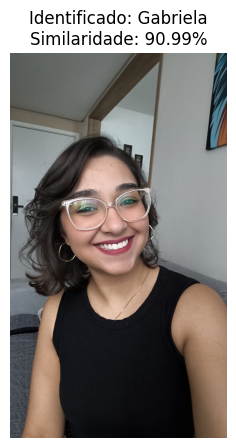

In [178]:
exibir_resultado_reconhecimento(
    imagem_teste,
    resultado
)

## Testando automáticamente para todas as pessoas

In [180]:
resultados_reconhecimento = []

for pessoa_real, dados in dataset.items():

    # pega a primeira imagem de teste
    imagem_teste = dados["teste"][0]

    resultado = reconhecer_rosto(
        imagem_teste,
        perfis_faciais
    )

    acertou = (
        resultado["pessoa"] == pessoa_real
    )

    resultados_reconhecimento.append({
        "pessoa_real": pessoa_real,
        "pessoa_identificada": resultado["pessoa"],
        "similaridade": resultado["similaridade"],
        "acertou": acertou
    })

    status = "CORRETO" if acertou else "INCORRETO"

    print(
        f"{pessoa_real:<20} -> "
        f"{resultado['pessoa']:<20} "
        f"| {resultado['similaridade']:.4f} "
        f"| {status}"
    )

Gabriela             -> Gabriela             | 0.9099 | CORRETO
Tom Holland          -> Tom Holland          | 0.7253 | CORRETO
Zendaya              -> Zendaya              | 0.9051 | CORRETO


Acompanhando os resultados

In [181]:
df_resultados = pd.DataFrame(resultados_reconhecimento)

df_resultados

,pessoa_real,pessoa_identificada,similaridade,acertou
0,Gabriela,Gabriela,0.909881,True
1,Tom Holland,Tom Holland,0.725343,True
2,Zendaya,Zendaya,0.905088,True


In [182]:
total = len(df_resultados)

acertos = df_resultados["acertou"].sum()

acuracia = acertos / total

print(f"Acertos: {acertos}/{total}")
print(f"Acurácia: {acuracia:.2%}")

Acertos: 3/3
Acurácia: 100.00%


# 6. Caso "Desconhecido"

Hoje nosso código responde apenas "Qual pessoa cadastrada é mais parecida?", mas precisamos responder "Existe alguma pessoa cadsatrada suficientemente parecida?"

In [ ]:
def reconhecer_rosto(
    caminho_imagem,
    perfis_faciais,
    limiar
):
    embedding_teste = extrair_embedding(
        caminho_imagem
    )

    similaridades = {}

    for pessoa, perfil in perfis_faciais.items():

        similaridade = calcular_similaridade(
            embedding_teste,
            perfil
        )

        similaridades[pessoa] = similaridade

    pessoa_mais_proxima = max(
        similaridades,
        key=similaridades.get
    )

    melhor_similaridade = similaridades[
        pessoa_mais_proxima
    ]

    if melhor_similaridade >= limiar:
        pessoa_identificada = pessoa_mais_proxima
    else:
        pessoa_identificada = "Desconhecido"

    return {
        "pessoa": pessoa_identificada,
        "pessoa_mais_proxima": pessoa_mais_proxima,
        "similaridade": melhor_similaridade,
        "similaridades": similaridades
    }

In [185]:
# Medindo os desconhecidos
resultados_desconhecidos = []

DESCONHECIDOS_DIR = DATASET_DIR / "desconhecidos"

for caminho in sorted(DESCONHECIDOS_DIR.glob("*")):

    if not caminho.is_file():
        continue

    embedding = extrair_embedding(caminho)

    similaridades = {}

    for pessoa, perfil in perfis_faciais.items():

        similaridades[pessoa] = calcular_similaridade(
            embedding,
            perfil
        )

    pessoa_mais_proxima = max(
        similaridades,
        key=similaridades.get
    )

    melhor_similaridade = similaridades[
        pessoa_mais_proxima
    ]

    resultados_desconhecidos.append({
        "imagem": caminho.name,
        "pessoa_mais_proxima": pessoa_mais_proxima,
        "similaridade": melhor_similaridade
    })

In [186]:
df_desconhecidos = pd.DataFrame(
    resultados_desconhecidos
)

df_desconhecidos

,imagem,pessoa_mais_proxima,similaridade
0,5_evelyn.png,Gabriela,0.651793


Separando o reconhecimento de decisão

In [ ]:
def reconhecer_rosto(
    caminho_imagem,
    perfis_faciais,
    limiar
):
    embedding_teste = extrair_embedding(caminho_imagem)

    similaridades = {}

    for pessoa, perfil in perfis_faciais.items():

        similaridade = calcular_similaridade(embedding_teste, perfil)

        similaridades[pessoa] = similaridade

    pessoa_mais_proxima = max(
        similaridades,
        key=similaridades.get
    )

    melhor_similaridade = similaridades[
        pessoa_mais_proxima
    ]

    reconhecido = melhor_similaridade >= limiar

    return {
        "pessoa": (pessoa_mais_proxima if reconhecido else "Desconhecido"),
        "pessoa_mais_proxima": pessoa_mais_proxima,
        "similaridade": melhor_similaridade,
        "similaridades": similaridades
    }

In [ ]:
# Limiar experimental inicial
# Este valor deverá ser recalibrado conforme novas imagens forem adicionadas ao dataset.
LIMIAR_RECONHECIMENTO = 0.69

In [ ]:
resultado = reconhecer_rosto(caminho_imagem, perfis_faciais, LIMIAR_RECONHECIMENTO)

Podemos criar uma função de calibração

In [ ]:
def calibrar_threshold(scores_conhecidos, scores_desconhecidos, inicio=0.0, fim=1.0, passo=0.001):
    resultados = []

    thresholds = np.arange(inicio, fim+passo, passo)

    for threshold in thresholds:
        # Conhecidos que foram corretamente reconhecidos
        conhecidos_aceitos = (scores_conhecidos >= threshold)

        # Desconhecidos que foram corretamente rejeitados
        desconhecidos_rejeitados = (scores_desconhecidos < threshold)

        # Taxa de acerto para conhecidos
        tpr = conhecidos_aceitos.mean()

        # Taxa de acerto para desconhecidos
        tnr = desconhecidos_rejeitados.mean()

        balanced_accuracy = (tpr + tnr) / 2

        resultados.append({
            "threshold": threshold,
            "taxa_conhecidos_aceitos": tpr,
            "taxa_desconhecidos_rejeitados": tnr,
            "balanced_accuracy": balanced_accuracy
        })

    df = pd.DataFrame(resultados)

    return df 

In [ ]:
df_thresholds = calibrar_threshold(scores_conhecidos, scores_desconhecidos)

Selecionamos o centro da faixa ótima

In [ ]:
# Descobrimos a melhor pontuação
melhor_score = df_thresholds["balanced_accuracy"].max()

# Encontramos todos os thresholds que atingiram a melhor pontuação
melhores_thresholds = df_thresholds[df_thresholds["balanced_accuracy"] == melhor_score]

# Pegamos o ponto central
threshold_otimo = melhores_thresholds["threshold"].median()

# 7. Avaliação do modelo

In [ ]:
# Conjunto único de resultados para conhecidos
resultados_avaliacao = []

for pessoa_real, dados in dataset.items():

    resultado = reconhecer_rosto(
        dados["teste"],
        perfis_faciais,
        LIMIAR_RECONHECIMENTO
    )

    predicao = resultado["pessoa"]

    resultados_avaliacao.append({
        "imagem": dados["teste"].name,
        "pessoa_real": pessoa_real,
        "predicao": predicao,
        "similaridade": resultado["similaridade"],
        "tipo": "Conhecida",
        "correto": predicao == pessoa_real
    })

In [ ]:
# Conjunto único de resultados para desconhecidos
for caminho in sorted(DESCONHECIDOS_DIR.glob("*")):

    if not caminho.is_file():
        continue

    resultado = reconhecer_rosto(
        caminho,
        perfis_faciais,
        LIMIAR_RECONHECIMENTO
    )

    predicao = resultado["pessoa"]

    resultados_avaliacao.append({
        "imagem": caminho.name,
        "pessoa_real": "Desconhecido",
        "predicao": predicao,
        "similaridade": resultado["similaridade"],
        "tipo": "Desconhecida",
        "correto": predicao == "Desconhecido"
    })

In [ ]:
# Base para as métricas de avaliação
df_avaliacao = pd.DataFrame(
    resultados_avaliacao
)

df_avaliacao

Acurácia geral

In [ ]:
acuracia = df_avaliacao["correto"].mean()

print(f"Acurácia geral: {acuracia:.2%}")

Taxa de reconhecimento dos conhecidos

In [ ]:
df_conhecidos = df_avaliacao[
    df_avaliacao["tipo"] == "Conhecida"
]

taxa_reconhecimento = (
    df_conhecidos["correto"].mean()
)

print(
    f"Taxa de reconhecimento: "
    f"{taxa_reconhecimento:.2%}"
)

Taxa de rejeição dos desconhecidos

In [ ]:
df_desconhecidos_avaliacao = df_avaliacao[
    df_avaliacao["tipo"] == "Desconhecida"
]

taxa_rejeicao = (
    df_desconhecidos_avaliacao["correto"].mean()
)

print(
    f"Taxa de rejeição de desconhecidos: "
    f"{taxa_rejeicao:.2%}"
)

Falsos positivos e falsos negativos

In [ ]:
# Falso positivo
# Pessoa desconhecida aceita como conhecida
falsos_positivos = df_avaliacao[
    (df_avaliacao["tipo"] == "Desconhecida")
    &
    (df_avaliacao["predicao"] != "Desconhecido")
]

In [ ]:
# Falso negativo
# Pessoa conhecida rejeitada como desconhecida
falsos_negativos = df_avaliacao[
    (df_avaliacao["tipo"] == "Conhecida")
    &
    (df_avaliacao["predicao"] == "Desconhecido")
]

In [ ]:
# Identificação incorreta
identificacoes_incorretas = df_avaliacao[
    (df_avaliacao["tipo"] == "Conhecida")
    &
    (df_avaliacao["predicao"] != "Desconhecido")
    &
    (
        df_avaliacao["predicao"]
        != df_avaliacao["pessoa_real"]
    )
]

RESUMO AUTOMÁTICA

In [ ]:
total = len(df_avaliacao)
acertos = df_avaliacao["correto"].sum()
erros = total - acertos

print("=" * 45)
print("AVALIAÇÃO DO MODELO")
print("=" * 45)

print(f"Amostras avaliadas: {total}")
print(f"Acertos: {acertos}")
print(f"Erros: {erros}")

print(
    f"Acurácia geral: "
    f"{acertos / total:.2%}"
)

print(
    f"Reconhecimento de conhecidos: "
    f"{taxa_reconhecimento:.2%}"
)

print(
    f"Rejeição de desconhecidos: "
    f"{taxa_rejeicao:.2%}"
)

print(
    f"Falsos positivos: "
    f"{len(falsos_positivos)}"
)

print(
    f"Falsos negativos: "
    f"{len(falsos_negativos)}"
)

print(
    f"Identificações incorretas: "
    f"{len(identificacoes_incorretas)}"
)

print(
    f"Threshold utilizado: "
    f"{LIMIAR_RECONHECIMENTO:.4f}"
)

Visualização dos resultados

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df_avaliacao["pessoa_real"],
    df_avaliacao["similaridade"]
)

plt.axhline(
    y=LIMIAR_RECONHECIMENTO,
    linestyle="--",
    label=(
        f"Threshold = "
        f"{LIMIAR_RECONHECIMENTO:.3f}"
    )
)

plt.xlabel("Pessoa real")
plt.ylabel("Similaridade")
plt.title(
    "Similaridade das imagens de avaliação"
)

plt.legend()
plt.grid()
plt.show()

### Limitações

Quantidade reduzida de pessoas e imagens. O conjunto atual possui poucas identidades e poucas imagens de avaliação. Portanto, os resultados não são suficientes para afirmar que o mesmo desempenho será mantido com uma base maior.

Threshold dependente do conjunto de calibração. O limiar foi obtido com base nas similaridades observadas. Conforme novas pessoas e imagens forem adicionadas, as distribuições podem mudar e o threshold precisa ser recalibrado.

Variações das imagens. Pose, iluminação, expressão facial, resolução, distância da câmera, oclusões e outros fatores podem alterar os embeddings e reduzir a similaridade de uma pessoa com seu próprio perfil.

Perfil baseado na média dos embeddings. A média das imagens fornece uma representação simples e adequada ao protótipo, mas pode perder informações quando uma mesma pessoa apresenta grande variação visual. Como preservamos os embeddings individuais, posteriormente podemos comparar outras estratégias.

Avaliação limitada de desconhecidos. Atualmente Evelyn representa apenas uma amostra desconhecida. Esse é provavelmente o ponto mais importante a melhorar antes da conclusão final.

Eu também mencionaria que o protótipo avalia reconhecimento facial, não mecanismos adicionais necessários em um sistema biométrico real, como prova de vida (liveness detection), proteção dos templates biométricos e tratamento operacional de tentativas inválidas.